# Challenge 2 — Steps 1-2: Explore and prepare the data
**Owner:** Daniel Ibarra · **Goal of this notebook:** understand the training data before modeling, then (Step 2) set up the shared preprocessing and validation that the whole team uses.

> Only `challenge2_train.csv` is used here. The test file is never opened in this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

## Piece 1: Exploratory Data Analysis (EDA)

### 1.1 Load the data
**What:** read the training file and look at its size and first rows. **Why:** confirm it loaded correctly and see what one row (one shopping session) looks like.

In [2]:
df = pd.read_csv("Data/challenge2_train.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (9247, 19)


,ID,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,4,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,7,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
4,9,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False


### 1.2 Column types
**What:** list each column's data type. **Why:** text columns (like `Month`) must be turned into numbers before modeling, and True/False columns need handling too.

In [3]:
df.dtypes.to_frame("dtype")

,dtype
ID,int64
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64


### 1.3 Missing values and duplicates
**What:** count empty cells, and rows that are exact copies of each other (ignoring `ID`). **Why:** blanks would need filling in Step 2, and many duplicates could make validation look better than it is.

In [4]:
print("Missing values in the whole table:", df.isna().sum().sum())
print("Duplicate rows (ignoring ID):", df.drop(columns="ID").duplicated().sum())

# What do the duplicates look like?
dups = df.drop(columns="ID")
dups = dups[dups.duplicated(keep=False)]
dups[["ProductRelated", "ProductRelated_Duration", "BounceRates", "PageValues", "Revenue"]].value_counts()

Missing values in the whole table: 0
Duplicate rows (ignoring ID): 81


ProductRelated  ProductRelated_Duration  BounceRates  PageValues  Revenue
1               0.0                      0.2          0.0         False      127
2               0.0                      0.2          0.0         False        9
Name: count, dtype: int64

The duplicates are all the same kind of visit: 1-2 product pages, 0 seconds, bounce rate 0.2, no purchase. Different people can easily produce identical rows like this, so we treat them as real separate sessions and **keep them**.

### 1.4 Target: buyers vs. non-buyers
**What:** count how many sessions ended in a purchase (`Revenue = True`). **Why:** if buyers are rare, accuracy is misleading, so we use F1 for `Revenue = True` instead.

,count,share
Revenue,,
False,7816,0.845
True,1431,0.155


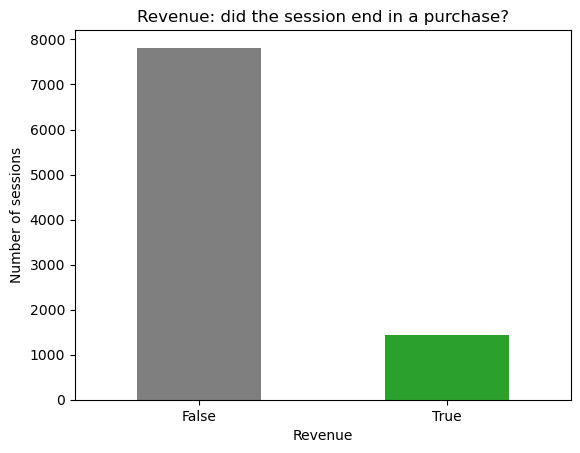

A model that always says 'no purchase' would be 84.5% accurate, but would catch 0 buyers (F1 = 0).


In [5]:
counts = df["Revenue"].value_counts()
share = df["Revenue"].value_counts(normalize=True).round(3)
display(pd.DataFrame({"count": counts, "share": share}))

counts.plot(kind="bar", color=["tab:gray", "tab:green"], rot=0)
plt.title("Revenue: did the session end in a purchase?")
plt.ylabel("Number of sessions")
plt.show()

print(f"A model that always says 'no purchase' would be {share[False]:.1%} accurate, but would catch 0 buyers (F1 = 0).")

### 1.5 Ranges of the numeric columns
**What:** min, median and max of each number column. **Why:** columns on very different scales (0.2 vs tens of thousands) confuse distance-based models like KNN and SVM, so they need scaling.

In [6]:
NUM_COLS = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

ranges = df[NUM_COLS].describe().T[["min", "50%", "max", "mean"]].rename(columns={"50%": "median"})
ranges["share_zero"] = (df[NUM_COLS] == 0).mean().round(2)
ranges.round(2)

,min,median,max,mean,share_zero
Administrative,0.0,1.00,27.00,2.31,0.47
Administrative_Duration,0.0,8.00,3398.75,81.17,0.48
Informational,0.0,0.00,24.00,0.50,0.79
Informational_Duration,0.0,0.00,2549.38,34.52,0.81
ProductRelated,0.0,18.00,705.00,31.36,0.00
ProductRelated_Duration,0.0,598.25,63973.52,1181.85,0.06
BounceRates,0.0,0.00,0.20,0.02,0.45
ExitRates,0.0,0.03,0.20,0.04,0.01
PageValues,0.0,0.00,361.76,5.98,0.78
SpecialDay,0.0,0.00,1.00,0.06,0.90


### 1.6 Category columns
**What:** how many different values each category column has, and what they are. **Why:** these get one-hot encoded in Step 2. `OperatingSystems`, `Browser`, `Region` and `TrafficType` are stored as numbers, but they are codes (like jersey numbers), not amounts.

In [7]:
CAT_COLS = ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region", "TrafficType"]

for col in CAT_COLS:
    values = sorted(df[col].unique().tolist())
    print(f"{col:17} {df[col].nunique():>2} values: {values}")

Month             10 values: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
VisitorType        3 values: ['New_Visitor', 'Other', 'Returning_Visitor']
Weekend            2 values: [False, True]
OperatingSystems   8 values: [1, 2, 3, 4, 5, 6, 7, 8]
Browser           13 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Region             9 values: [1, 2, 3, 4, 5, 6, 7, 8, 9]
TrafficType       20 values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


In [8]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df["Month"].value_counts().reindex(month_order).to_frame("sessions").T

Month,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
sessions,141,1445,2550,204,319,319,345,415,2213,1296


### 1.7 What predicts buying?
**What:** the purchase rate inside different groups. **Why:** shows which columns carry the most signal, which helps the team choose features and explain results later.

In [9]:
has_page_value = df["PageValues"] > 0
by_pv = df.groupby(has_page_value)["Revenue"].agg(sessions="size", buy_rate="mean")
by_pv.index = by_pv.index.map({False: "PageValues = 0", True: "PageValues > 0"})
by_pv.round(3)

,sessions,buy_rate
PageValues,,
PageValues = 0,7189,0.036
PageValues > 0,2058,0.569


In [10]:
by_visitor = df.groupby("VisitorType")["Revenue"].agg(sessions="size", buy_rate="mean")
by_visitor.round(3)

,sessions,buy_rate
VisitorType,,
New_Visitor,1265,0.247
Other,72,0.181
Returning_Visitor,7910,0.140


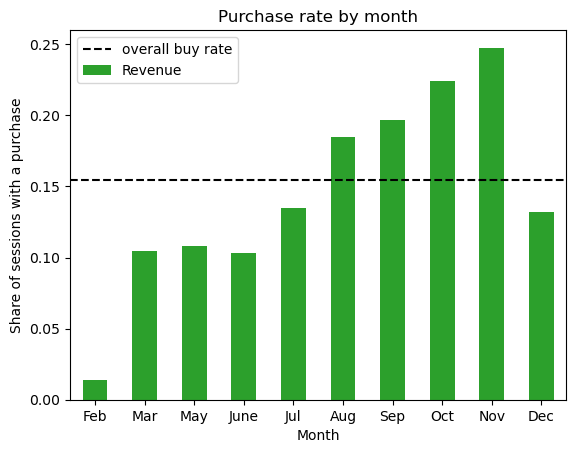

Month,Feb,Mar,May,June,Jul,Aug,Sep,Oct,Nov,Dec
buy_rate,0.014,0.104,0.108,0.103,0.135,0.185,0.197,0.224,0.248,0.132


In [11]:
by_month = df.groupby("Month")["Revenue"].mean().reindex(month_order)
by_month.plot(kind="bar", color="tab:green", rot=0)
plt.axhline(df["Revenue"].mean(), color="black", linestyle="--", label="overall buy rate")
plt.title("Purchase rate by month")
plt.ylabel("Share of sessions with a purchase")
plt.legend()
plt.show()
by_month.round(3).to_frame("buy_rate").T

### 1.8 Summary of Piece 1
| Finding | What it means for Step 2 and modeling |
|---|---|
| 9,247 sessions, 17 usable columns (`ID` excluded, `Revenue` is the target). **No missing values.** | No filling-in needed. We keep a simple imputer anyway, as a safety net. |
| 81 duplicate rows, all 0-second bounce visits with no purchase. | Kept: they look like real, separate sessions. |
| **Imbalanced target:** 84.5% no purchase, 15.5% purchase. | Use **F1 for `Revenue = True`** and *stratified* folds (every fold keeps ~15.5% buyers). Accuracy alone would be misleading. |
| Numeric columns are on very different scales (`BounceRates` max 0.2, `ProductRelated_Duration` max 63,974), and most are skewed with many zeros. | **Scale** numeric columns for Logistic Regression, KNN and SVM. Tree models don't need it. |
| `Month`, `VisitorType`, `Weekend`, plus 4 code columns (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) are categories. `Month` has only 10 months (no Jan/Apr; June is spelled `"June"`). | **One-hot encode** all 7 category columns, ignoring any value not seen during training. |
| **`PageValues` is the strongest clue:** 3.6% buy when it's 0 vs 56.9% when it's above 0. New visitors buy more often (24.7%) than returning ones (14.0%). Nov has the highest buy rate (24.8%), Feb the lowest (1.4%). | Expect models to lean on `PageValues`. Good material for explaining the final model. |

## Piece 2: Preprocessing
Models only understand numbers on sensible scales, so before modeling we:
- **Scale the 10 numeric columns** (`StandardScaler`: each column gets mean 0 and standard deviation 1). Only for models that measure distances or weigh features by size: Logistic Regression, KNN, SVM (and Naïve Bayes). Tree models split on thresholds, so they don't need it.
- **One-hot encode the 7 category columns:** each category value becomes its own 0/1 column (e.g. `Month_Nov` = 1 for November sessions). A category that never appeared in training becomes all zeros instead of crashing.
- **Fill blanks** (median for numbers, most common value for categories). There are none today; this is a safety net.

The code lives in `helpers.py` so the whole team uses exactly the same steps.

### 2.1 Load the data through the shared helper
**What:** `load_data()` returns `X` (the 17 feature columns, no `ID`) and `y` (`Revenue` as 0/1, where 1 = purchase). **Why:** everyone starts from the same columns.

In [12]:
from helpers import NUM_COLS, CAT_COLS, CV, load_data, make_preprocessor, evaluate, results_table, cv_confusion_matrix

X, y = load_data()
print("X:", X.shape, "| y:", y.shape, "| buyers (y = 1):", y.sum())

X: (9247, 17) | y: (9247,) | buyers (y = 1): 1431


### 2.2 What the preprocessor produces
**What:** run the preprocessor once on the training data to see its output. **Why:** to check it works and see how many columns the models receive.

This is only a demonstration. During validation the preprocessor is never fitted on all the data at once: it sits inside a `Pipeline` with the model, so in each fold it learns the scaling and categories **only from that fold's training part** (see Piece 3).

In [13]:
prep = make_preprocessor(scale=True)
X_prepped = prep.fit_transform(X)

names = prep.get_feature_names_out()
print("Columns before:", X.shape[1], "-> after:", X_prepped.shape[1])
print("  numeric (scaled):", sum(n.startswith("num__") for n in names))
print("  one-hot category columns:", sum(n.startswith("cat__") for n in names))

Columns before: 17 -> after: 75
  numeric (scaled): 10
  one-hot category columns: 65


In [14]:
# Scaling check: before vs after for two columns on very different scales
before = X[["BounceRates", "ProductRelated_Duration"]].agg(["mean", "std"])
after = pd.DataFrame(X_prepped[:, [NUM_COLS.index("BounceRates"), NUM_COLS.index("ProductRelated_Duration")]],
                     columns=before.columns).agg(["mean", "std"])
pd.concat({"before scaling": before, "after scaling": after}).round(3)

BounceRates  ProductRelated_Duration
before scaling mean        0.022                 1181.848
               std         0.049                 1908.101
after scaling  mean       -0.000                   -0.000
               std         1.000                    1.000

## Piece 3: Validation strategy
We can't check ourselves on the test file (no answers), so we hide part of the training data and test on it.

- **5-fold cross-validation:** split the training data into 5 parts. Train on 4, test on the 5th, and repeat so every part is tested once. The score is the average of the 5 tests, which is more reliable than a single split.
- **Stratified:** every fold keeps the same share of buyers (~15.5%). Without it, a fold could get unusually few buyers and give a misleading score.
- **Same folds for everyone** (`random_state=42`), so the team's results are directly comparable.
- **Main metric: F1 for `Revenue = True`.** We also report precision, recall, accuracy and the confusion matrix. Comparing **train F1 with CV F1** shows overfitting: a model that scores much higher on data it trained on than on held-out data is memorizing.

### 3.1 Check the folds
**What:** size and buyer share of each validation fold. **Why:** confirms stratification works.

In [15]:
folds = []
for i, (train_idx, val_idx) in enumerate(CV.split(X, y), start=1):
    folds.append({"fold": i, "train rows": len(train_idx), "validation rows": len(val_idx),
                  "buyer share in validation": y.iloc[val_idx].mean()})
pd.DataFrame(folds).set_index("fold").round(3)

,train rows,validation rows,buyer share in validation
fold,,,
1,7397,1850,0.155
2,7397,1850,0.155
3,7398,1849,0.155
4,7398,1849,0.155
5,7398,1849,0.155


## Piece 4: Baselines and the shared `evaluate()` helper
`evaluate(name, model, X, y, scale=...)` runs preprocessing + model through the 5 shared folds and returns one row: train F1, CV F1 (mean ± std), CV precision, recall, accuracy and fit time. `results_table(rows)` turns rows into a table sorted by CV F1.

**Baselines** are "dumb" models with no learning. Every real model has to beat them:
- **Always "no purchase"** (`most_frequent`): high accuracy, F1 = 0. This is the accuracy trap from Piece 1.
- **Random guess at the buyer rate** (`stratified`): says "purchase" for a random ~15.5% of sessions. Its F1 is roughly what pure chance gets.

In [16]:
from sklearn.dummy import DummyClassifier

rows = [
    evaluate("Baseline: always 'no purchase'", DummyClassifier(strategy="most_frequent"), X, y),
    evaluate("Baseline: random guess at buyer rate", DummyClassifier(strategy="stratified", random_state=42), X, y),
]
results_table(rows)

,train_f1,cv_f1,cv_f1_std,cv_precision,cv_recall,cv_accuracy,fit_time_s
model,,,,,,,
Baseline: random guess at buyer rate,0.157,0.141,0.015,0.139,0.143,0.730,0.053
Baseline: always 'no purchase',0.000,0.000,0.000,0.000,0.000,0.845,0.063


### 4.1 Confusion matrix of the "always no" baseline
**What:** counts of right and wrong predictions, using predictions on held-out folds. **Why:** shows *why* its F1 is 0: it never predicts a purchase, so it misses all 1,431 buyers even though it gets 84.5% of sessions right.

In [17]:
cv_confusion_matrix(DummyClassifier(strategy="most_frequent"), X, y)

,predicted no purchase (0),predicted purchase (1)
actual no purchase (0),7816,0
actual purchase (1),1431,0


### 4.2 How teammates use this
In your own notebook inside the `Challenge 2/` folder:
```python
from helpers import load_data, evaluate, results_table, cv_confusion_matrix, make_model_pipeline, CV, SCORING
from sklearn.neighbors import KNeighborsClassifier

X, y = load_data()
rows = [evaluate("KNN", KNeighborsClassifier(), X, y, scale=True)]   # scale=False for tree models
results_table(rows)
```
For Grid Search, wrap the model so preprocessing stays inside each fold, and prefix parameter names with `model__`:
```python
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(make_model_pipeline(KNeighborsClassifier(), scale=True),
                    {"model__n_neighbors": [5, 11, 21]}, cv=CV, scoring=SCORING["f1"])
grid.fit(X, y)
```

## Summary of Steps 1-2
- **Data:** 9,247 sessions, no missing values, 15.5% buyers. `PageValues` is the strongest signal.
- **Preprocessing:** 10 numeric columns (scaled for LogReg/KNN/SVM/Naïve Bayes) + 7 category columns one-hot encoded → 75 model inputs. Always inside a `Pipeline`, so nothing leaks between folds.
- **Validation:** stratified 5-fold CV, `random_state=42`, F1 for `Revenue = True` as the main metric, plus precision, recall, accuracy, train-vs-CV F1 and confusion matrices.
- **Baselines to beat:** F1 = 0 for "always no purchase" (despite 84.5% accuracy) and 0.14 for random guessing (CV F1 0.141).